# 07 · LightGBM

Same gradient-boosting idea as XGBoost, engineered for speed on large data:
- **Histogram-based splits**: features are bucketed into ≤255 bins, so split finding is cheap.
- **Leaf-wise growth**: grows the leaf with the biggest loss reduction next, instead of a whole level. Gets lower loss with fewer leaves but can overfit small data, so **`num_leaves` is the main complexity knob** (not `max_depth`).
- GOSS / EFB tricks: sample rows by gradient size, bundle sparse features.
- Native categorical handling (pandas `category` dtype).

| Param | Role | Typical |
|---|---|---|
| `num_leaves` | complexity (≈ 2^depth) | 15–255 |
| `min_child_samples` | min rows per leaf; key regulariser for small data | 5–200 |
| `learning_rate` + early stopping | as always | 0.01–0.1 |
| `subsample` (+`subsample_freq=1`), `colsample_bytree` | randomness | 0.5–1.0 |
| `reg_lambda`, `reg_alpha` | L2 / L1 | 1e-3–10 |

Set `verbose=-1` to silence it.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
import lightgbm as lgb
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss

adult = fetch_openml("adult", version=2, as_frame=True)
X = adult.data
y = (adult.target == ">50K").astype(int)
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.2, stratify=y_trval, random_state=SEED)
cat_cols = list(X.select_dtypes("category").columns)
print("categorical columns:", cat_cols)

categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## 1. Fit with early stopping
Categorical columns with `category` dtype are detected automatically.

In [3]:
clf = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
        callbacks=[lgb.early_stopping(200, verbose=False)])
p = clf.predict_proba(X_test)[:, 1]
print(f"trees: {clf.best_iteration_} | test AUC {roc_auc_score(y_test, p):.4f} | log loss {log_loss(y_test, p):.4f}")

trees: 273 | test AUC 0.9287 | log loss 0.2759


## 2. `num_leaves`: the complexity dial

In [4]:
rows = []
for nl in [4, 8, 16, 31, 63, 127, 255]:
    m = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.05, num_leaves=nl, random_state=SEED, verbose=-1)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    rows.append((nl, m.best_iteration_, log_loss(y_val, m.predict_proba(X_val)[:, 1])))
res = pd.DataFrame(rows, columns=["num_leaves", "best trees", "val log loss"]).set_index("num_leaves")
res

,best trees,val log loss
num_leaves,,
4,1578,0.2752
8,662,0.2738
16,367,0.2735
31,206,0.2730
63,149,0.2734
127,118,0.2760
255,87,0.2813


More leaves → fewer trees needed, but past a point validation loss rises. There's usually a broad flat optimum, so don't over-tune.

## 3. Native categoricals vs one-hot

In [5]:
import time

def fit_eval(Xtr, Xva, Xte):
    t = time.time()
    m = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.05, random_state=SEED, verbose=-1)
    m.fit(Xtr, y_train, eval_set=[(Xva, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return roc_auc_score(y_test, m.predict_proba(Xte)[:, 1]), Xtr.shape[1], time.time() - t

onehot = pd.get_dummies(X, columns=cat_cols, dtype=float)
oh = [onehot.loc[d.index] for d in (X_train, X_val, X_test)]
for name, args in [("native category", (X_train, X_val, X_test)), ("one-hot", oh)]:
    auc, ncol, sec = fit_eval(*args)
    print(f"{name:>16}: AUC {auc:.4f} | {ncol:3d} columns | {sec:.1f}s")

 native category: AUC 0.9292 |  14 columns | 0.6s


         one-hot: AUC 0.9288 | 105 columns | 0.6s


Similar accuracy here, but native handling keeps the data compact. With high-cardinality categoricals (thousands of levels) native categorical splits can overfit; raise `min_data_per_group` / `cat_smooth`, or use CatBoost (next notebook).

## 4. Built-in cross-validation: `lgb.cv`
The low-level API returns the CV curve, so you get the best number of rounds averaged across folds.

In [6]:
params = dict(objective="binary", learning_rate=0.05, num_leaves=31, min_child_samples=20,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, metric="auc", verbose=-1, seed=SEED)
cv_res = lgb.cv(params, lgb.Dataset(X_trval, y_trval), num_boost_round=5000, nfold=5, stratified=True,
                callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"best rounds: {len(cv_res['valid auc-mean'])} | CV AUC {cv_res['valid auc-mean'][-1]:.4f} ± {cv_res['valid auc-stdv'][-1]:.4f}")

best rounds: 227 | CV AUC 0.9289 ± 0.0023


## 5. Monotone constraints: domain knowledge as a guard-rail

If you *know* the prediction should only go up with a feature (e.g. house value with income, default risk with debt), enforce it.
It protects against noisy wiggles, especially where data is thin, and makes the model easier to defend.

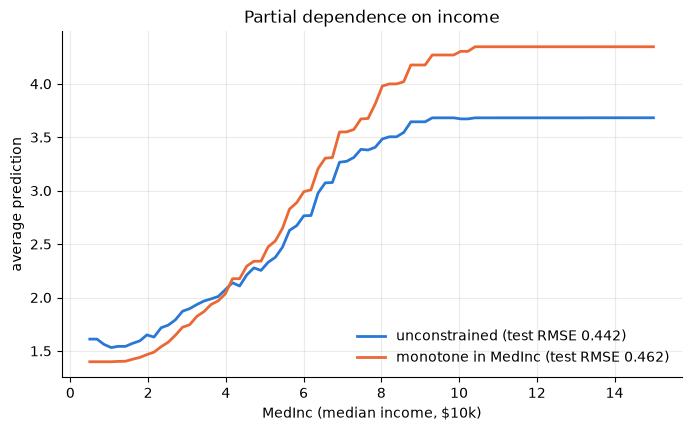

In [7]:
from sklearn.datasets import fetch_california_housing
from sklearn.inspection import partial_dependence

Xc, yc = fetch_california_housing(return_X_y=True, as_frame=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=SEED)
mono = [1 if c == "MedInc" else 0 for c in Xc.columns]

fig, ax = plt.subplots()
for k, (name, constraint) in enumerate([("unconstrained", None), ("monotone in MedInc", mono)]):
    m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=5,
                          monotone_constraints=constraint, random_state=SEED, verbose=-1).fit(Xc_tr, yc_tr)
    pd_res = partial_dependence(m, Xc_tr, ["MedInc"], grid_resolution=80, percentiles=(0.0, 1.0))
    rm = np.sqrt(np.mean((yc_te - m.predict(Xc_te)) ** 2))
    ax.plot(pd_res["grid_values"][0], pd_res["average"][0], color=PALETTE[k], label=f"{name} (test RMSE {rm:.3f})")
ax.set_xlabel("MedInc (median income, $10k)"); ax.set_ylabel("average prediction"); ax.legend()
ax.set_title("Partial dependence on income")
plt.show()

Here the unconstrained model was *already* almost monotone, and forcing it costs some test accuracy: the constraint also stops the model using income in non-monotone interactions. Constraints are not free accuracy. They buy **robustness and defensibility**, and pay off most where data is thin or noisy, or when a regulator or user must trust the shape of the response. Always compare CV scores with and without.

## Takeaways
- LightGBM is usually the **fastest** strong model: a great default for medium/large tabular data.
- Tune `num_leaves` and `min_child_samples` first; use early stopping for the number of trees.
- `lgb.cv` gives a fold-averaged best iteration.
- Use `monotone_constraints` where theory says so and the data is thin; check the CV cost.
- Other objectives: `regression_l1`, `huber`, `quantile` (with `alpha`), `poisson`, `tweedie`, `lambdarank`.